In [3]:
import sys
import pandas as pd
import numpy as np

print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Environment ready!")

Python: 3.13.9
Pandas: 2.3.3
NumPy: 2.3.5
Environment ready!


## Step 1.1: Read data files

In [4]:
from pathlib import Path
import pandas as pd

# Locate the raw data folder
project = Path.cwd()
if not (project / "data_raw").exists():
    project = project.parent

data_dir = project / "data_raw"

# Load annual datasets
years = range(2021, 2026)

dfs = []
for year in years:
    file = data_dir / f"hrl_load_metered_{year}.csv"
    df_year = pd.read_csv(file)
    df_year["source_year"] = year
    dfs.append(df_year)
    print(f"{year}: {df_year.shape[0]:,} rows")

# Combine all five years
df = pd.concat(dfs, ignore_index=True)

print("\nCombined shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())

2021: 262,800 rows
2022: 262,800 rows
2023: 262,800 rows
2024: 263,520 rows
2025: 262,800 rows

Combined shape: (1314720, 9)

Columns:
['datetime_beginning_utc', 'datetime_beginning_ept', 'nerc_region', 'mkt_region', 'zone', 'load_area', 'mw', 'is_verified', 'source_year']


,datetime_beginning_utc,datetime_beginning_ept,nerc_region,mkt_region,zone,load_area,mw,is_verified,source_year
0,1/1/2021 5:00:00 AM,1/1/2021 12:00:00 AM,RFC,MIDATL,AE,AECO,957.066,True,2021
1,1/1/2021 5:00:00 AM,1/1/2021 12:00:00 AM,RFC,WEST,AEP,AEPAPT,3953.135,True,2021
2,1/1/2021 5:00:00 AM,1/1/2021 12:00:00 AM,RFC,WEST,AEP,AEPIMP,2788.492,True,2021
3,1/1/2021 5:00:00 AM,1/1/2021 12:00:00 AM,RFC,WEST,AEP,AEPKPT,682.262,True,2021
4,1/1/2021 5:00:00 AM,1/1/2021 12:00:00 AM,RFC,WEST,AEP,AEPOPT,5816.635,True,2021


## step 1.2: filter PJM RTO data

In [5]:
# Filter PJM RTO total load
rto = df[
    (df["mkt_region"] == "RTO") &
    (df["zone"] == "RTO") &
    (df["load_area"] == "RTO")
].copy()

# Convert UTC timestamps
rto["datetime_beginning_utc"] = pd.to_datetime(
    rto["datetime_beginning_utc"],
    utc=True
)

# Sort chronologically
rto = rto.sort_values("datetime_beginning_utc").reset_index(drop=True)

print("RTO dataset shape:", rto.shape)
print("Start:", rto["datetime_beginning_utc"].min())
print("End:", rto["datetime_beginning_utc"].max())

display(rto.head())

RTO dataset shape: (43824, 9)
Start: 2021-01-01 05:00:00+00:00
End: 2026-01-01 04:00:00+00:00


,datetime_beginning_utc,datetime_beginning_ept,nerc_region,mkt_region,zone,load_area,mw,is_verified,source_year
0,2021-01-01 05:00:00+00:00,1/1/2021 12:00:00 AM,RTO,RTO,RTO,RTO,81842.644,False,2021
1,2021-01-01 06:00:00+00:00,1/1/2021 1:00:00 AM,RTO,RTO,RTO,RTO,80005.690,False,2021
2,2021-01-01 07:00:00+00:00,1/1/2021 2:00:00 AM,RTO,RTO,RTO,RTO,78940.704,False,2021
3,2021-01-01 08:00:00+00:00,1/1/2021 3:00:00 AM,RTO,RTO,RTO,RTO,78563.968,False,2021
4,2021-01-01 09:00:00+00:00,1/1/2021 4:00:00 AM,RTO,RTO,RTO,RTO,79136.453,False,2021


## step 1.3: check

In [7]:
# Missing values
print("Missing values:")
print(rto.isnull().sum())

# Duplicate UTC timestamps
duplicates = rto["datetime_beginning_utc"].duplicated().sum()
print("\nDuplicate UTC timestamps:", duplicates)

# Check hourly continuity
expected_hours = pd.date_range(
    start=rto["datetime_beginning_utc"].min(),
    end=rto["datetime_beginning_utc"].max(),
    freq="h",
    tz="UTC"
)

missing_hours = expected_hours.difference(
    pd.DatetimeIndex(rto["datetime_beginning_utc"])
)

print("Expected hours:", len(expected_hours))
print("Actual hours:", len(rto))
print("Missing hours:", len(missing_hours))

# Verify load values
print("\nLoad summary:")
print(rto["mw"].describe())

# Verification status
print("\nVerification status:")
print(rto["is_verified"].value_counts(dropna=False))

Missing values:
datetime_beginning_utc    0
datetime_beginning_ept    0
nerc_region               0
mkt_region                0
zone                      0
load_area                 0
mw                        0
is_verified               0
source_year               0
dtype: int64

Duplicate UTC timestamps: 0
Expected hours: 43824
Actual hours: 43824
Missing hours: 0

Load summary:
count     43824.000000
mean      90728.991181
std       16087.555950
min       58684.756000
25%       79605.571750
50%       88041.915000
75%       99751.727750
max      160154.429000
Name: mw, dtype: float64

Verification status:
is_verified
False    43824
Name: count, dtype: int64


## Step 1.4: Annual load statistics

In [ ]:
annual_stats = rto.groupby("source_year")["mw"].agg(
    ["count", "mean", "std", "min", "max"]
)

print("Annual Load Statistics (MW):")
display(annual_stats.round(2))

print("\nNegative or zero load values:",
      (rto["mw"] <= 0).sum())

print("\nMaximum load:")
display(rto.nlargest(5, "mw")[
    ["datetime_beginning_utc", "mw", "source_year"]
])

print("\nMinimum load:")
display(rto.nsmallest(5, "mw")[
    ["datetime_beginning_utc", "mw", "source_year"]
])

Annual Load Statistics (MW):


,count,mean,std,min,max
source_year,,,,,
2021,8760,89347.48,16111.18,58684.76,148770.35
2022,8760,90766.62,16117.02,60753.58,147715.66
2023,8760,87915.84,14254.72,59756.84,147178.13
2024,8784,91075.05,16021.60,61787.81,152551.30
2025,8760,94539.01,17043.80,63296.87,160154.43



Negative or zero load values: 0

Maximum load:


,datetime_beginning_utc,mw,source_year
39232,2025-06-23 21:00:00+00:00,160154.429,2025
39233,2025-06-23 22:00:00+00:00,159861.939,2025
39231,2025-06-23 20:00:00+00:00,158370.411,2025
39256,2025-06-24 21:00:00+00:00,158097.632,2025
39234,2025-06-23 23:00:00+00:00,157651.849,2025



Minimum load:


,datetime_beginning_utc,mw,source_year
3243,2021-05-16 08:00:00+00:00,58684.756,2021
3242,2021-05-16 07:00:00+00:00,58713.820,2021
2403,2021-04-11 08:00:00+00:00,59277.029,2021
3244,2021-05-16 09:00:00+00:00,59297.562,2021
2907,2021-05-02 08:00:00+00:00,59386.344,2021


## step 1.5: Visualize historical electricity demand

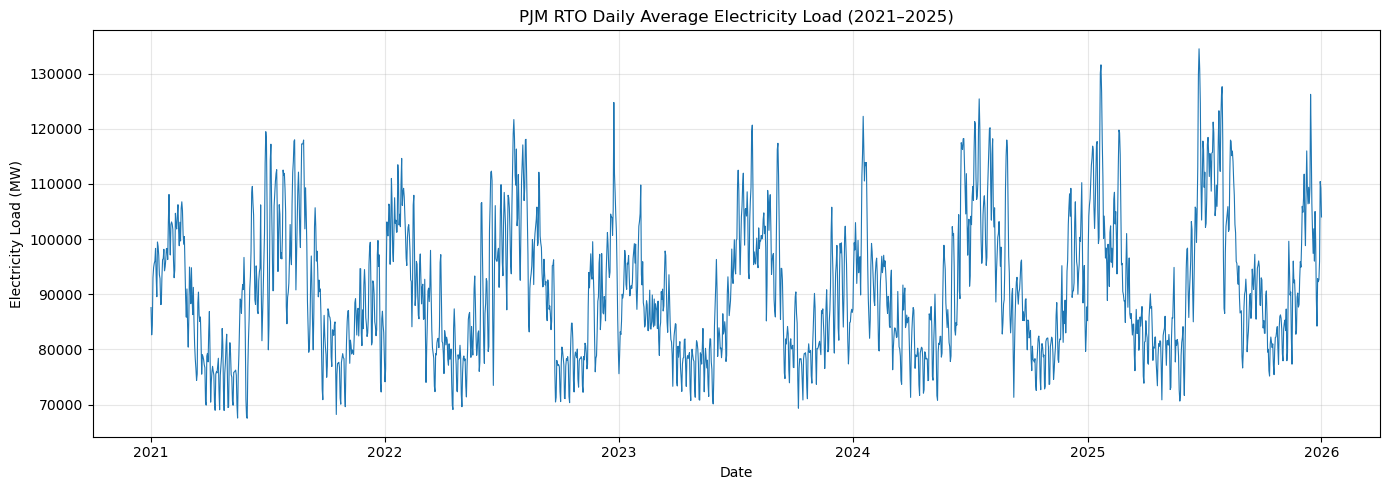

In [11]:
import matplotlib.pyplot as plt

# Use the original UTC timestamp column
rto["datetime_beginning_utc"] = pd.to_datetime(
    rto["datetime_beginning_utc"], utc=True
)

rto = rto.sort_values("datetime_beginning_utc")

# Calculate daily average load
daily_load = (
    rto.set_index("datetime_beginning_utc")["mw"]
       .resample("D")
       .mean()
)

plt.figure(figsize=(14, 5))

plt.plot(daily_load.index, daily_load.values, linewidth=0.8)

plt.title("PJM RTO Daily Average Electricity Load (2021–2025)")
plt.xlabel("Date")
plt.ylabel("Electricity Load (MW)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Historical Electricity Load Trends (2021–2025)

The daily average electricity load shows clear seasonal patterns, with higher demand generally occurring during summer and winter and lower demand during spring and fall. Daily load also fluctuates considerably within each season. The higher load peaks observed in 2025 suggest potential challenges when forecasting future demand. These patterns motivate the use of calendar features, historical load lags, and rolling statistics in subsequent machine learning models.

## Step 1.6: Prepare and save the cleaned dataset

In [12]:
from pathlib import Path

# Create timezone-aware Eastern local timestamps
rto["datetime_ept"] = (
    rto["datetime_beginning_utc"]
       .dt.tz_convert("America/New_York")
)

# Keep relevant columns
cleaned = rto[
    [
        "datetime_beginning_utc",
        "datetime_ept",
        "mw",
        "source_year",
        "is_verified"
    ]
].copy()

cleaned = cleaned.sort_values(
    "datetime_beginning_utc"
).reset_index(drop=True)

# Locate project folder
project = Path.cwd()
if not (project / "data_raw").exists():
    project = project.parent

output_dir = project / "data_processed"
output_dir.mkdir(exist_ok=True)

output_file = output_dir / "pjm_rto_hourly_2021_2025.csv"

cleaned.to_csv(output_file, index=False)

print("Saved to:", output_file)
print("Shape:", cleaned.shape)

display(cleaned.head())

Saved to: /Users/jamella/Desktop/27fall/ml/data_source/electricity-demand-forecasting/data_processed/pjm_rto_hourly_2021_2025.csv
Shape: (43824, 5)


,datetime_beginning_utc,datetime_ept,mw,source_year,is_verified
0,2021-01-01 05:00:00+00:00,2021-01-01 00:00:00-05:00,81842.644,2021,False
1,2021-01-01 06:00:00+00:00,2021-01-01 01:00:00-05:00,80005.690,2021,False
2,2021-01-01 07:00:00+00:00,2021-01-01 02:00:00-05:00,78940.704,2021,False
3,2021-01-01 08:00:00+00:00,2021-01-01 03:00:00-05:00,78563.968,2021,False
4,2021-01-01 09:00:00+00:00,2021-01-01 04:00:00-05:00,79136.453,2021,False
